# Time to recovered discharge in Nara, Mali

My mission is to turn African healthcare data into evidence that governments, NGOs, and researchers can use. I started in Nara because the cohort links what was known at admission with how long nutrition care lasted.

I estimate days to discharge for children who eventually recovered. That covers one part of the demand for care. Adding other discharge outcomes and data from more districts is future work that could help inform wider funding decisions.

To reproduce the analysis, use the locked environment in `summative/` and put the original Zenodo CSV in `summative/data/`. The README explains how to verify the original file.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

summative_dir = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents, Path.cwd() / "summative")
    if (folder / "linear_regression" / "multivariate.ipynb").is_file()
)
data_dir = summative_dir / "data"
source = pd.read_csv(data_dir / "Mali_Cohort_Study.csv", na_values=["."])

assert source["AnonID"].notna().all() and source["AnonID"].is_unique
source.shape

(27800, 58)

## Who is in the modeling cohort?

I focused on recovered health-centre cases with a positive duration. Site is fixed in that group. I kept the record ID for checking the splits and the inpatient transfer flag for checking errors after fitting. Follow-up measurements, treatment totals, and other outcomes are excluded from the inputs because they are recorded after admission.

I added weight-for-age z-score (WAZ), height-for-age z-score (HAZ), and the recorded admission category to the eight-input reference. The admission category reproduces the programme threshold of MUAC below 115 mm or oedema. It lets a linear model represent the threshold explicitly.

In [2]:
numeric_features = ["adm_age", "adm_kg", "adm_cm", "adm_muac"]
categorical_features = ["adm_sex", "adm_oedema_YN", "adm_referral"]
shared_features = numeric_features + categorical_features
z_score = "adm_whz06"
z_score_bounds = {
    "adm_whz06": (-5, 5),
    "adm_waz06": (-6, 5),
    "adm_haz06": (-6, 6),
}
model_numeric_features = [*numeric_features, *z_score_bounds]
model_categorical_features = [*categorical_features, "adm_category"]
model_features = model_numeric_features + model_categorical_features
target = "recovered_los"

eligible = source.loc[
    source["adm_site"].eq("Health Center")
    & source["cured"].eq(1)
    & source[target].gt(0)
]
cohort = (
    eligible[["AnonID", *model_features, target, "transfer_inpatient"]]
    .dropna(subset=shared_features)
    .set_index("AnonID")
    .sort_index()
)

# Flag only the affected z-score so the other admission inputs remain usable.
score_audit = []
for field, (lower, upper) in z_score_bounds.items():
    values = cohort[field]
    flagged = values.notna() & ~values.between(lower, upper)
    score_audit.append({
        "Z-score": field,
        "Originally missing": values.isna().sum(),
        "Outside plausibility limits": flagged.sum(),
    })
    cohort.loc[flagged, field] = np.nan

admission_rule = cohort["adm_muac"].lt(115) | cohort["adm_oedema_YN"].eq(1)
assert cohort["adm_category"].eq(admission_rule.map({True: 1, False: 2})).all()
assert len(model_features) == 11
print(f"{len(eligible):,} eligible records, {len(cohort):,} with the seven shared inputs")
pd.DataFrame(score_audit).set_index("Z-score")

20,484 eligible records, 20,057 with the seven shared inputs


,Originally missing,Outside plausibility limits
Z-score,,
adm_whz06,55,952
adm_waz06,15,206
adm_haz06,0,405


## Split before fitting anything

The CSV has no admission date. I used a fixed random split and stratified on oedema so the few records in that category would be represented. About 70% go to training, 20% to the held-out test, and 10% to the retraining demo. The demo rows stay outside fitting, tuning, and model selection.

In [3]:
seed = 42
train_and_demo, test = train_test_split(
    cohort, test_size=0.20, random_state=seed, stratify=cohort["adm_oedema_YN"]
)
train, retraining_batch = train_test_split(
    train_and_demo,
    test_size=0.125,
    random_state=seed,
    stratify=train_and_demo["adm_oedema_YN"],
)

splits = {"train": train, "test": test, "retraining": retraining_batch}
split_ids = pd.Index([record_id for rows in splits.values() for record_id in rows.index])
assert split_ids.is_unique and len(split_ids) == len(cohort)

pd.DataFrame({
    name: {
        "Rows": len(rows),
        "With z-score": rows[z_score].notna().sum(),
        "Oedema cases": rows["adm_oedema_YN"].eq(1).sum(),
    }
    for name, rows in splits.items()
}).T

,Rows,With z-score,Oedema cases
train,14039,13347,10
test,4012,3798,3
retraining,2006,1905,2


## Explore recovery duration

Each bar groups training cases into a seven-day interval. The held-out test and retraining groups stay separate from this exploration.

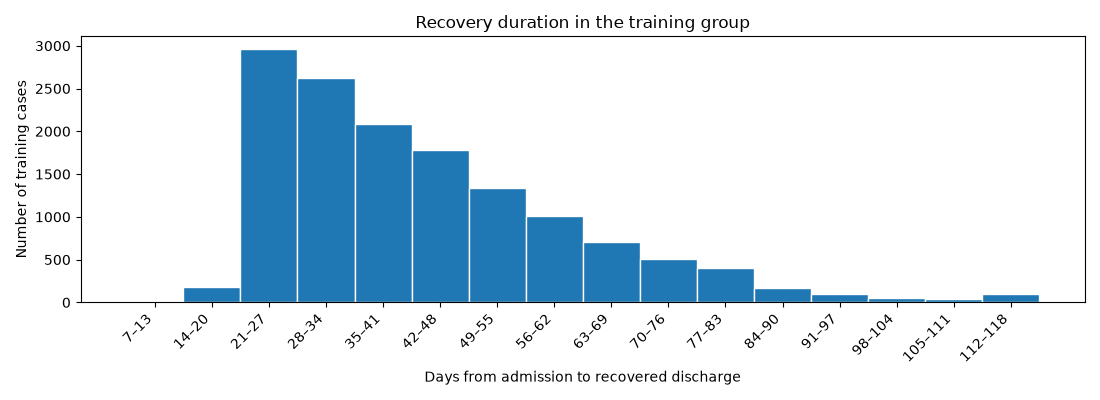

In [4]:
import matplotlib.pyplot as plt

week_starts = list(range(7, 113, 7))
week_labels = [f"{day}–{day + 6}" for day in week_starts]

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(train[target], bins=[*week_starts, 119], edgecolor="white")
ax.set_xticks([day + 3.5 for day in week_starts], week_labels, rotation=45, ha="right")
ax.set(xlabel="Days from admission to recovered discharge",
       ylabel="Number of training cases",
       title="Recovery duration in the training group")
fig.tight_layout()
plt.show()

The tallest bar covers 21–27 days and contains 2,962 training cases. The median is 35 days, and 1,365 cases (about 10%) took at least 70 days. I'll use the training mean as a baseline for the MSE comparison and also report mean absolute error in days so we can see the typical size of a prediction error.

## Compare numeric inputs

The heatmap uses training rows and computes each correlation from cases with both values present. WHZ, WAZ, and HAZ are weight-for-height, weight-for-age, and height-for-age z-scores.

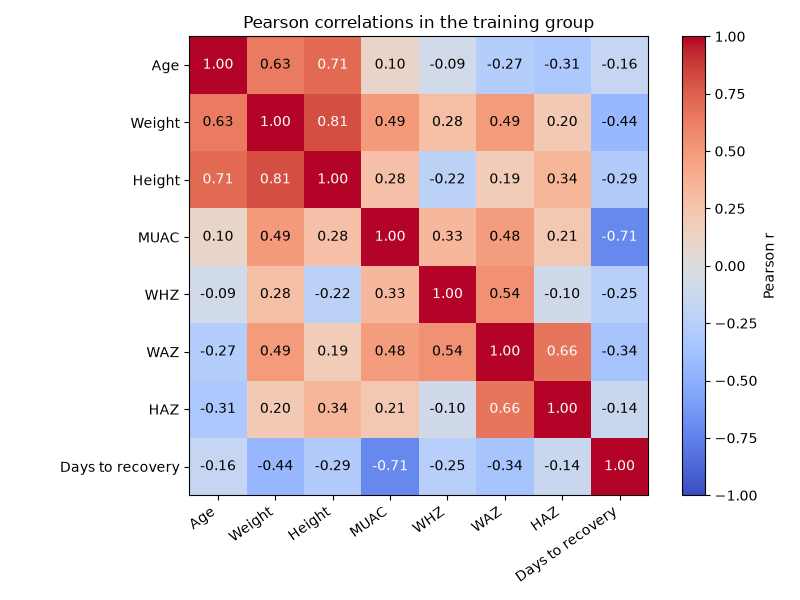

In [5]:
from matplotlib.colors import TwoSlopeNorm

# Pearson correlation describes linear relationships between numeric columns.
numeric_columns = [*model_numeric_features, target]
correlations = train[numeric_columns].corr()
labels = ["Age", "Weight", "Height", "MUAC", "WHZ", "WAZ", "HAZ", "Days to recovery"]

fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(
    correlations, cmap="coolwarm", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
)
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Pearson correlations in the training group")

for row, values in enumerate(correlations.to_numpy()):
    for column, value in enumerate(values):
        color = "white" if abs(value) >= 0.65 else "black"
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

MUAC has the strongest linear relationship with duration (r = -0.71). Smaller admission MUAC tends to go with longer stays, so I'll use it for the one-feature scatter plots. The heatmap shows one input at a time against the target, so I'll test whether WHZ adds value by comparing models on the same records with and without it.

## Compare admission categories

Counts and median durations show how the training cases differ by sex, oedema status, and referral source.

In [6]:
category_summary = pd.concat(
    {
        feature: train.groupby(feature)[target].agg(
            cases="size", median_days="median"
        )
        for feature in categorical_features
    },
    names=["Admission field", "Category"],
)
category_summary.rename(
    columns={"cases": "Training cases", "median_days": "Median recovery days"}
)

Training cases  Median recovery days
Admission field Category                                          
adm_sex         Female                  7494                  35.0
                Male                    6545                  35.0
adm_oedema_YN   0                      14029                  35.0
                1                         10                  39.5
adm_referral    CHW - Relais            5625                  35.0
                Family MUAC             5415                  35.0
                Other                    417                  35.0
                Walk-in                 2582                  35.0

Only 10 training cases have oedema, so their median can shift with just a few records. I’ll keep oedema as a candidate and avoid drawing strong conclusions about that group. I’ll one-hot encode referral source so the model can use each category without imposing an order.

## Examine admission MUAC before and after fitting

MUAC is mid-upper arm circumference, measured in millimetres. Both panels show the same training records. Darker areas show where recorded values overlap.

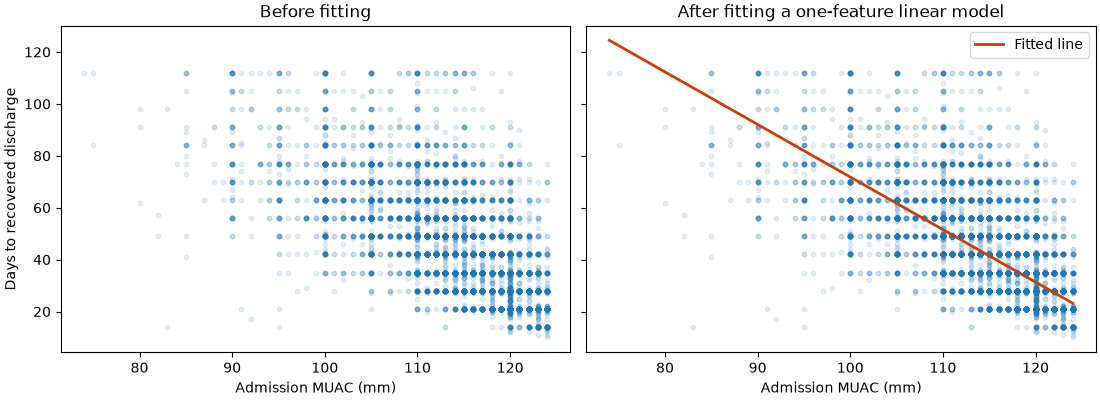

In [7]:
from sklearn.linear_model import LinearRegression

muac = train[["adm_muac"]]
durations = train[target]
muac_model = LinearRegression().fit(muac, durations)
line_inputs = muac.drop_duplicates().sort_values("adm_muac")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax in axes:
    ax.scatter(muac["adm_muac"], durations, s=10, alpha=0.12)
    ax.set_xlabel("Admission MUAC (mm)")

axes[0].set(title="Before fitting", ylabel="Days to recovered discharge")
axes[1].set_title("After fitting a one-feature linear model")
axes[1].plot(
    line_inputs["adm_muac"], muac_model.predict(line_inputs), color="#c2410c",
    linewidth=2, label="Fitted line",
)
axes[1].legend()
plt.show()

The fitted line slopes downward, in line with the negative correlation in the heatmap. Cases with the same admission MUAC still vary widely in recovery duration, so I'll check whether the multivariate models improve predictions on the held-out test rows.

## Set a mean-duration baseline

The baseline predicts the same number of days for every case. That number is the training mean, which minimizes squared error among constant predictions. We'll score this baseline on the same held-out rows as the four models when their settings are final.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(train[model_features], train[target])
baseline_train_predictions = baseline.predict(train[model_features])

pd.Series({
    "Constant prediction (days)": baseline.constant_.item(),
    "Training MSE (days squared)": mean_squared_error(train[target], baseline_train_predictions),
    "Training MAE (days)": mean_absolute_error(train[target], baseline_train_predictions),
}).round(2)

Constant prediction (days)      40.19
Training MSE (days squared)    342.57
Training MAE (days)             14.67
dtype: float64

## Prepare numeric and categorical inputs

I treat z-scores outside the WHO/UNICEF plausibility limits as missing. Each fit uses its own training medians to fill the missing scores, then scales the numeric inputs and one-hot encodes the categories. The app can accept a blank z-score when one is unavailable. [WHO/UNICEF anthropometry guidance](https://data.unicef.org/wp-content/uploads/2019/05/Anthropometry-children-under-5-guidance-English_2019.pdf)

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(numeric_columns, categorical_columns):
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        [
            ("numeric", numeric_pipeline, numeric_columns),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ],
        verbose_feature_names_out=False,
    )


preview_preprocessor = make_preprocessor(model_numeric_features, model_categorical_features)
encoded_train = preview_preprocessor.fit_transform(train[model_features])
print(f"{len(model_features)} raw inputs become {encoded_train.shape[1]} model columns")
pd.DataFrame(
    encoded_train[:5],
    columns=preview_preprocessor.get_feature_names_out(),
).round(2)

11 raw inputs become 17 model columns


,adm_age,adm_kg,adm_cm,adm_muac,adm_whz06,adm_waz06,adm_haz06,adm_sex_Female,adm_sex_Male,adm_oedema_YN_0,adm_oedema_YN_1,adm_referral_CHW - Relais,adm_referral_Family MUAC,adm_referral_Other,adm_referral_Walk-in,adm_category_1,adm_category_2
0,-1.06,0.58,-1.39,-0.86,3.94,2.71,-0.08,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1.09,2.07,1.10,1.29,1.39,0.83,-0.44,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.39,0.41,0.06,0.98,0.22,0.51,0.23,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.79,0.25,-0.17,0.67,0.87,1.72,1.28,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.55,-1.41,-0.93,-1.02,-1.16,-2.25,-2.13,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


## Check what the extra features contribute

I compare the eight-input reference and the eleven-input version on the same five folds within the training group. Each model fits its own preprocessing in each fold. The held-out test set stays separate until the final comparison.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

fit_rows, validation_rows = train_test_split(
    train, test_size=0.20, random_state=seed, stratify=train["adm_oedema_YN"]
)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(
    train, train["adm_oedema_YN"]
))
feature_checks = {}
for name, numeric_columns, category_columns in (
    ("Eight inputs", [*numeric_features, z_score], categorical_features),
    ("Eleven inputs", model_numeric_features, model_categorical_features),
):
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(numeric_columns, category_columns)),
        ("regression", LinearRegression()),
    ])
    feature_checks[name] = -cross_val_score(
        pipeline, train[numeric_columns + category_columns], train[target],
        cv=folds, scoring="neg_mean_squared_error",
    )

feature_scores = pd.DataFrame(feature_checks, index=pd.RangeIndex(1, 6, name="Fold"))
feature_scores.loc["Mean"] = feature_scores.mean()
feature_scores.round(2)

,Eight inputs,Eleven inputs
Fold,,
1,161.87,161.60
2,160.74,159.28
3,161.57,160.82
4,169.31,167.07
5,167.14,165.16
Mean,164.13,162.79


The eight-input reference averaged 164.13 days squared MSE across five folds. The eleven-input version averaged 162.79. I use the same eleven inputs for the four-model comparison so the models are working with the same information.

## Tune gradient descent on training-side validation

Compare three constant learning rates, three L2 regularization strengths, and checkpoints after 10, 30, and 80 passes through the fitting rows. A learning rate controls the size of each update. L2 regularization discourages large coefficients. Each trial sees the same row order in each epoch so the settings can be compared directly.

In [11]:
from itertools import product

from sklearn.linear_model import SGDRegressor

sgd_preprocessor = make_preprocessor(model_numeric_features, model_categorical_features)
fit_inputs = sgd_preprocessor.fit_transform(fit_rows[model_features])
validation_inputs = sgd_preprocessor.transform(validation_rows[model_features])
fit_days = fit_rows[target].to_numpy()

epoch_checkpoints = (10, 30, 80)
sgd_trials = []
for rate, alpha in product((0.001, 0.005, 0.01), (0.0001, 0.01, 0.1)):
    estimator = SGDRegressor(
        learning_rate="constant", eta0=rate, penalty="l2", alpha=alpha,
        shuffle=False, random_state=seed,
    )
    rng = np.random.default_rng(seed)
    for epoch in range(1, max(epoch_checkpoints) + 1):
        order = rng.permutation(len(fit_days))
        estimator.partial_fit(fit_inputs[order], fit_days[order])
        if epoch in epoch_checkpoints:
            prediction = estimator.predict(validation_inputs)
            sgd_trials.append({
                "learning_rate": rate,
                "alpha": alpha,
                "epochs": epoch,
                "validation_mse": mean_squared_error(validation_rows[target], prediction),
            })

sgd_results = pd.DataFrame(sgd_trials).sort_values(
    ["validation_mse", "epochs"], ignore_index=True
)
best_sgd = sgd_results.iloc[0]
sgd_results.round({"validation_mse": 3})

,learning_rate,alpha,epochs,validation_mse
0,0.001,0.0001,80,151.085
1,0.001,0.0100,80,151.115
2,0.001,0.0100,30,151.131
3,0.001,0.0001,30,151.187
4,0.001,0.0100,10,151.550
5,0.001,0.0001,10,151.829
6,0.001,0.1000,10,151.932
7,0.005,0.0001,80,152.096
8,0.001,0.1000,80,152.195
9,0.005,0.1000,10,152.324


I selected a learning rate of 0.001, an L2 alpha of 0.0001, and 80 epochs because that combination gave the lowest validation MSE at 151.09 days squared. I fixed those settings before looking at the test loss curve.

Holding the other settings fixed gives a clearer picture. At alpha 0.0001 and 80 epochs, raising the learning rate from 0.001 to 0.01 increased MSE from 151.09 to 157.21. At the winning learning rate and epoch count, raising alpha to 0.1 increased it to 152.20. At the winning rate and alpha, going from 10 to 80 epochs reduced MSE from 151.83 to 151.09.

## Track SGD loss across epochs

Refit the preprocessor on the full training group and train SGD for the epoch count chosen on validation. Record both curves after each pass through the training rows. The test curve is a diagnostic. Model settings and the final epoch were fixed before computing it.

Epoch 80: train MSE 162.76, test MSE 160.66


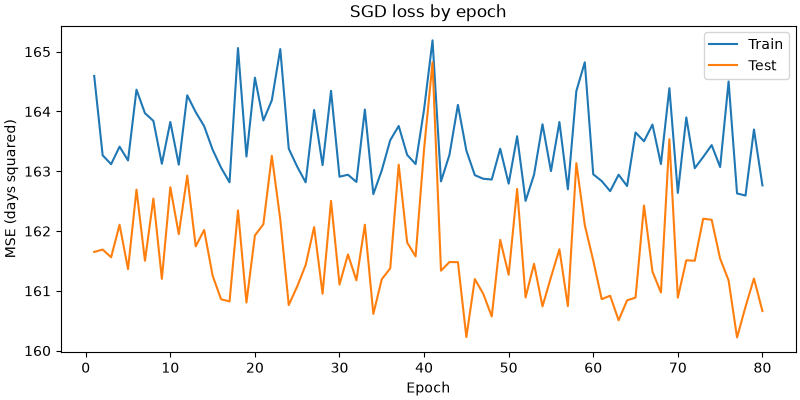

In [12]:
final_sgd_preprocessor = make_preprocessor(model_numeric_features, model_categorical_features)
train_inputs = final_sgd_preprocessor.fit_transform(train[model_features])
test_inputs = final_sgd_preprocessor.transform(test[model_features])
train_days = train[target].to_numpy()
test_days = test[target].to_numpy()

final_sgd = SGDRegressor(
    learning_rate="constant", eta0=float(best_sgd["learning_rate"]),
    penalty="l2", alpha=float(best_sgd["alpha"]), shuffle=False, random_state=seed,
)
rng = np.random.default_rng(seed)
train_mse, test_mse = [], []
for epoch in range(int(best_sgd["epochs"])):
    order = rng.permutation(len(train_days))
    final_sgd.partial_fit(train_inputs[order], train_days[order])
    train_mse.append(mean_squared_error(train_days, final_sgd.predict(train_inputs)))
    test_mse.append(mean_squared_error(test_days, final_sgd.predict(test_inputs)))

sgd_pipeline = Pipeline([
    ("preprocessing", final_sgd_preprocessor),
    ("regression", final_sgd),
])

epochs = range(1, len(train_mse) + 1)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(epochs, train_mse, label="Train")
ax.plot(epochs, test_mse, label="Test")
ax.set(xlabel="Epoch", ylabel="MSE (days squared)", title="SGD loss by epoch")
ax.legend()
plt.show()

print(f"Epoch {len(train_mse)}: train MSE {train_mse[-1]:.2f}, test MSE {test_mse[-1]:.2f}")

The curves record what happens after each pass through the training data. SGD sees a new row order each epoch, so loss can rise or fall. I use the validation-selected 80-epoch result in the comparison.

## Compare models on the same held-out cases

All four models use the same eleven admission inputs. The tree and forest use a minimum of 20 training records per leaf to limit highly specific rules. The forest averages 100 trees. Compare models by test MSE and report test MAE in days for planning context.

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

models = {"SGDRegressor": sgd_pipeline}
for estimator in (
    LinearRegression(),
    DecisionTreeRegressor(min_samples_leaf=20, random_state=seed),
    RandomForestRegressor(n_estimators=100, min_samples_leaf=20, random_state=seed, n_jobs=-1),
):
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(model_numeric_features, model_categorical_features)),
        ("regression", estimator),
    ])
    models[type(estimator).__name__] = pipeline.fit(train[model_features], train[target])

scores = []
for name, model in {"Mean baseline": baseline, **models}.items():
    train_prediction = model.predict(train[model_features])
    test_prediction = model.predict(test[model_features])
    scores.append({
        "Model": name,
        "Train MSE (days squared)": mean_squared_error(train[target], train_prediction),
        "Test MSE (days squared)": mean_squared_error(test[target], test_prediction),
        "Test MAE (days)": mean_absolute_error(test[target], test_prediction),
    })

model_scores = pd.DataFrame(scores).set_index("Model")
winner_name = model_scores.loc[list(models), "Test MSE (days squared)"].idxmin()
winning_pipeline = models[winner_name]
print(f"Lowest test MSE among the four models: {winner_name}")

muac_test_mse = mean_squared_error(test[target], muac_model.predict(test[["adm_muac"]]))
print(f"For context, the one-feature MUAC fit had test MSE {muac_test_mse:.2f} days squared.")
model_scores.sort_values("Test MSE (days squared)").round(2)

Lowest test MSE among the four models: LinearRegression
For context, the one-feature MUAC fit had test MSE 165.63 days squared.


,Train MSE (days squared),Test MSE (days squared),Test MAE (days)
Model,,,
LinearRegression,162.36,160.52,9.18
SGDRegressor,162.76,160.66,9.16
RandomForestRegressor,133.46,163.73,9.18
DecisionTreeRegressor,134.78,180.20,9.66
Mean baseline,342.57,356.90,14.82


LinearRegression gave the lowest test MSE at 160.52 days squared, about 55% below the mean baseline. Its MAE was 9.18 days, a more direct way to describe the size of a miss. The MUAC-only fit reached 165.63 days squared, so that one measurement provides a strong reference.

The two linear fits can use the strong downward trend in MUAC. The single tree fits the training cases more closely, but its higher test error suggests some splits are specific to training. Averaging multiple trees improves on the single tree. I used test MSE as the selection criterion for all four.

## Check error by inpatient transfer status

Use transfer status to check the winning model's errors after selection. This status is recorded during treatment, so the pipeline still uses admission inputs only.

In [14]:
transfer_scores = []
for status, group in test.groupby("transfer_inpatient"):
    predicted_days = winning_pipeline.predict(group[model_features])
    transfer_scores.append({
        "Inpatient transfer": "Yes" if status == 1 else "No",
        "Test cases": len(group),
        "Mean absolute error (days)": mean_absolute_error(group[target], predicted_days),
        "Mean error (predicted minus recorded days)": (predicted_days - group[target]).mean(),
    })

pd.DataFrame(transfer_scores).set_index("Inpatient transfer").round(2)

,Test cases,Mean absolute error (days),Mean error (predicted minus recorded days)
Inpatient transfer,,,
No,3891,8.62,0.55
Yes,121,27.16,-20.69


The model underpredicted by 20.7 days on average among the 121 test cases that transferred. The overall error hides that gap. I would check whether better information at admission can reduce it or whether a separate follow-up model would be more useful.

## Save and reload the winning pipeline

I save the estimator with its fitted preprocessing. The reload check uses the same single-row prediction function as the API.

In [15]:
import sys

from joblib import dump, load

api_dir = summative_dir / "API"
sys.path.insert(0, str(api_dir))
from model_io import predict_one

model_path = api_dir / "best_model.pkl"
dump(winning_pipeline, model_path)
raw_admission = test[model_features].iloc[0].to_dict()
prediction = predict_one(load(model_path), raw_admission)
expected = winning_pipeline.predict(test[model_features].iloc[[0]])[0]
assert np.isclose(prediction, expected)
print(f"Saved {winner_name} pipeline to API/{model_path.name}")
print(f"Predicted: {prediction:.1f} days | Recorded: {test[target].iloc[0]:g} days")

Saved LinearRegression pipeline to API/best_model.pkl
Predicted: 37.4 days | Recorded: 35 days


## Export rows for the retraining demo

The API needs the original fitting rows because the winning linear model is refitted when new labels arrive. Export the eleven admission inputs and the recorded duration. Keep the separately reserved upload in the ignored data folder. The test rows and record IDs stay out of both exports.

In [16]:
export_columns = [*model_features, target]
training_export = model_path.with_name("training_rows.csv.gz")
demo_export = data_dir / "retraining_batch.csv"

train.to_csv(
    training_export, columns=export_columns, index=False,
    compression={"method": "gzip", "mtime": 0},
)
retraining_batch.to_csv(demo_export, columns=export_columns, index=False)
print(f"Original training rows: {len(train):,} → API/{training_export.name}")
print(f"Separate labelled demo rows: {len(retraining_batch):,} → data/{demo_export.name}")

Original training rows: 14,039 → API/training_rows.csv.gz
Separate labelled demo rows: 2,006 → data/retraining_batch.csv
